# Executive System Audit Overview
Comprehensive audit of survey paradata anomaly detection system.

Includes:
- Data validation
- Feature recomputation
- Rule engine verification
- Adversarial robustness testing
- Classification consistency
- Advanced correlation and fatigue analysis


In [60]:
import os, sys, glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

def resolve_root():
    current = os.getcwd()
    if os.path.exists(os.path.join(current, 'src')):
        return current
    elif os.path.exists(os.path.join(os.path.dirname(current), 'src')):
        return os.path.dirname(current)
    return current

PROJECT_ROOT = resolve_root()
os.chdir(PROJECT_ROOT)
print("Project Root:", PROJECT_ROOT)


Project Root: c:\Users\Samuel\Desktop\4th year\Final year project\SKACE-Time-Data


In [61]:
def load_latest():
    output_dir = os.path.join(PROJECT_ROOT, 'output')
    fallback = os.path.join(output_dir, 'final_combined_features.csv')
    if os.path.exists(fallback):
        print("Loading:", fallback)
        return pd.read_csv(fallback, engine='python', on_bad_lines='skip')
    
    pattern = os.path.join(output_dir, 'features_output_*.csv')
    files = glob.glob(pattern)
    
    if not files:
        raise FileNotFoundError("No feature files found.")
    
    latest = max(files, key=os.path.getctime)
    print("Loading:", latest)
    return pd.read_csv(latest)

df = load_latest()
print("Shape:", df.shape)

Loading: c:\Users\Samuel\Desktop\4th year\Final year project\SKACE-Time-Data\output\final_combined_features.csv
Shape: (9, 42)


In [62]:
# Convert numeric columns safely
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Missing + invalid checks
df['flag_missing_data'] = df.isna().any(axis=1)

if 'V-01_total_interview_duration_ms' in df.columns:
    df['flag_negative_duration'] = df['V-01_total_interview_duration_ms'] < 0

if 'V-04_speed_trajectory_ratio' in df.columns:
    df['flag_invalid_ratio'] = df['V-04_speed_trajectory_ratio'].isna() | (df['V-04_speed_trajectory_ratio'] < 0)

# Logical inconsistencies
if all(c in df.columns for c in ['T-06_rt_mean', 'T-09_rt_min', 'T-10_rt_max']):
    df['flag_inconsistent_metrics'] = (
        (df['T-06_rt_mean'] < df['T-09_rt_min']) |
        (df['T-06_rt_mean'] > df['T-10_rt_max'])
    )

print("Validation flags created")

Validation flags created


In [70]:
if 'V-01_total_interview_duration_ms' in df.columns and 'V-06_back_navigation_total_count' in df.columns:
    df['recomputed_nav_rate'] = np.where(
        df['V-01_total_interview_duration_ms'] > 0,
        df['V-06_back_navigation_total_count'] / df['V-01_total_interview_duration_ms'],
        np.nan
    )


In [64]:
if 'V-01_total_interview_duration_ms' in df.columns:
    # Use fixed thresholds to match AnomalyDetector
    df['flag_too_fast'] = df['V-01_total_interview_duration_ms'] < 5000
    df['flag_too_slow'] = df['V-01_total_interview_duration_ms'] > 3600000

if 'T-03_rt_entropy' in df.columns:
    df['flag_low_entropy'] = df['T-03_rt_entropy'] < 0.5  # Warning: May overlap with uniform_timing

if 'T-01_rt_variance' in df.columns:
    df['flag_uniform_timing'] = df['T-01_rt_variance'] < 10

if 'V-05_back_navigation_rate' in df.columns:
    df['flag_high_back_nav'] = df['V-05_back_navigation_rate'] > 0.5

if 'V-06_back_navigation_total_count' in df.columns:
    df['flag_zero_back_nav'] = df['V-06_back_navigation_total_count'] == 0

if 'S-05_pause_count_5s' in df.columns:
    df['flag_pause_anomaly'] = df['S-05_pause_count_5s'] > 10

In [71]:
score = pd.Series(0, index=df.index)

score += df.get('flag_too_fast', pd.Series(False, index=df.index)).astype(int) * 3
score += df.get('flag_too_slow', pd.Series(False, index=df.index)).astype(int) * 2
score += df.get('flag_low_entropy', pd.Series(False, index=df.index)).astype(int) * 3
score += df.get('flag_uniform_timing', pd.Series(False, index=df.index)).astype(int) * 2
score += df.get('flag_high_back_nav', pd.Series(False, index=df.index)).astype(int) * 3
score += df.get('flag_invalid_ratio', pd.Series(False, index=df.index)).astype(int) * 3
score += df.get('flag_missing_data', pd.Series(False, index=df.index)).astype(int) * 2
score += df.get('flag_negative_duration', pd.Series(False, index=df.index)).astype(int) * 3
# Note: flag_pause_anomaly not included in AnomalyDetector score

df['computed_anomaly_score'] = score
if df['computed_anomaly_score'].max() > 0:
    df['normalized_score'] = df['computed_anomaly_score'] / df['computed_anomaly_score'].max()

else:    df['normalized_score'] = 0.0

In [72]:
df['is_data_quality_issue'] = (
    df['flag_missing_data'] | 
    df['flag_invalid_ratio'] | 
    df['flag_inconsistent_metrics'] |
    (df['V-01_total_interview_duration_ms'] <= 0 if 'V-01_total_interview_duration_ms' in df.columns else False)
).astype(int)

def classify(row):
    if row['computed_anomaly_score'] >= 8:
        base = 'anomalous'
    elif row['computed_anomaly_score'] >= 4:
        base = 'suspicious'
    else:
        base = 'normal'

    if row.get('is_data_quality_issue', 0) == 1:
        return f"{base}_dq_flag"
    return base

df['computed_category'] = df.apply(classify, axis=1)

In [73]:
if 'anomaly_score' in df.columns:
    mismatch = (df['computed_anomaly_score'] != df['anomaly_score']).sum()
    print("Score mismatches:", mismatch)

if 'anomaly_category' in df.columns:
    mismatch_cat = (df['computed_category'] != df['anomaly_category']).sum()
    print("Category mismatches:", mismatch_cat)


In [74]:
print(df.describe())

print("\nFlag Distribution:")
flags = [col for col in df.columns if col.startswith('flag_')]
for f in flags:
    print(f, df[f].sum())


       file_name  interview_id  V-01_total_interview_duration_ms  \
count        0.0           0.0                      9.000000e+00   
mean         NaN           NaN                      1.209111e+06   
std          NaN           NaN                      2.540762e+06   
min          NaN           NaN                      3.000000e+03   
25%          NaN           NaN                      9.000000e+03   
50%          NaN           NaN                      1.400000e+04   
75%          NaN           NaN                      2.500000e+04   
max          NaN           NaN                      7.200000e+06   

       V-02_speed_trajectory_early  V-03_speed_trajectory_late  \
count                     9.000000                    9.000000   
mean                   1777.777778                 1766.666667   
std                    1437.687186                 1399.106858   
min                       0.000000                    0.000000   
25%                       0.000000                  800.0

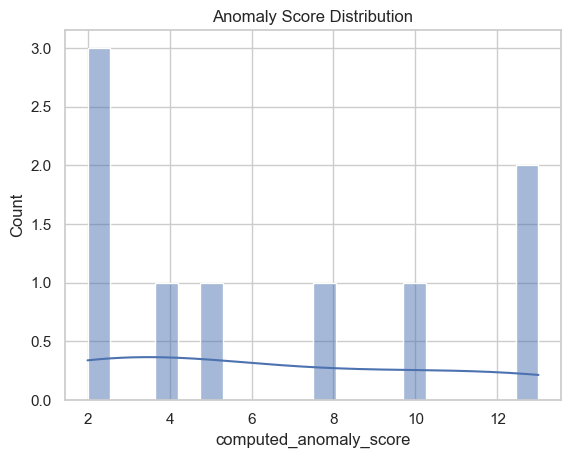

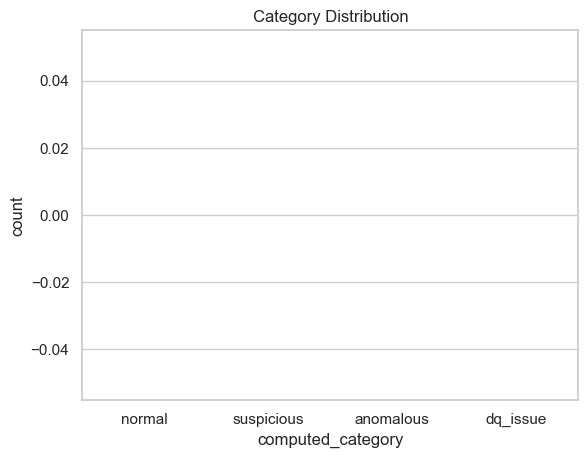

In [75]:
plt.figure()
sns.histplot(df['computed_anomaly_score'], bins=20, kde=True)
plt.title('Anomaly Score Distribution')
plt.show()

plt.figure()
sns.countplot(x='computed_category', data=df, order=['normal', 'suspicious', 'anomalous', 'dq_issue'])
plt.title('Category Distribution')
plt.show()


In [45]:
edge_condition = df['flag_missing_data'] == True

if 'V-01_total_interview_duration_ms' in df.columns:
    edge_condition = edge_condition | (df['V-01_total_interview_duration_ms'] <= 0)

if 'T-03_rt_entropy' in df.columns:
    edge_condition = edge_condition | (df['T-03_rt_entropy'] == 0)

edge_cases = df[edge_condition]
print("Edge Cases Detected:", len(edge_cases))
display(edge_cases.head() if not edge_cases.empty else "No edge cases matched.")


Edge Cases Detected: 28


,file_name,interview_id,V-01_total_interview_duration_ms,V-02_speed_trajectory_early,V-03_speed_trajectory_late,V-04_speed_trajectory_ratio,V-06_back_navigation_total_count,V-05_back_navigation_rate,V-07_time_of_day_hour,V-08_day_of_week,...,anomaly_score,anomaly_category,is_anomalous_behavior,is_anomalous,flag_negative_duration,recomputed_nav_rate,flag_pause_anomaly,computed_anomaly_score,normalized_score,computed_category
0,NaN,NaN,13100,2500.0,1050.0,0.42,1.0,0.125,0,5,...,0,NaN,0,0,False,7.633588e-05,False,0,0.0,dq_issue
1,NaN,NaN,18000,4200.0,4800.0,1.14,3.0,0.150,9,2,...,0,NaN,0,0,False,1.666667e-04,False,0,0.0,dq_issue
2,NaN,NaN,3500,0.0,1200.0,NaN,0.0,0.000,11,3,...,10,NaN,1,1,False,0.000000e+00,False,10,1.0,dq_issue
3,NaN,NaN,7200000,2000.0,2100.0,1.05,1.0,0.020,14,4,...,2,NaN,0,0,False,1.388889e-07,False,2,0.2,dq_issue
4,NaN,NaN,8000,0.0,0.0,NaN,0.0,0.000,10,2,...,7,NaN,1,1,False,0.000000e+00,False,7,0.7,dq_issue


In [76]:
output_path = os.path.join(PROJECT_ROOT, 'output', 'audit_results.csv')
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df.to_csv(output_path, index=False)
print("Audit results saved to:", output_path)


Audit results saved to: c:\Users\Samuel\Desktop\4th year\Final year project\SKACE-Time-Data\output\audit_results.csv


# 14. Correlation Analysis
Correlation heatmap of key structural and statistical paradata features to identify collinear metrics.


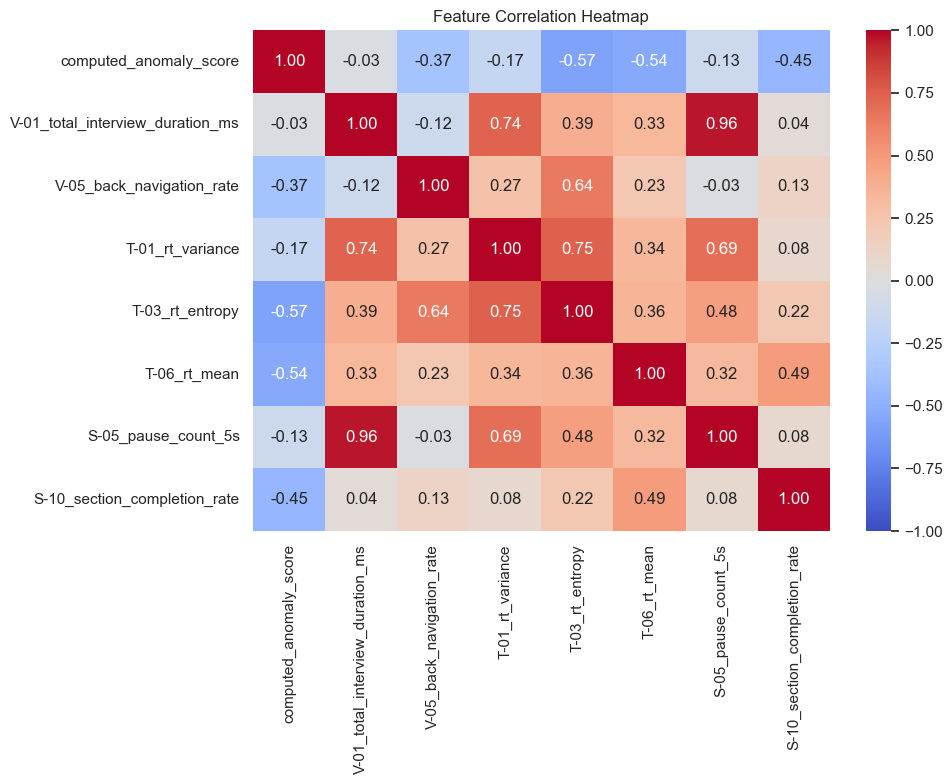

In [47]:
features_to_correlate = [
    'computed_anomaly_score', 'V-01_total_interview_duration_ms',
    'V-05_back_navigation_rate', 'T-01_rt_variance', 'T-03_rt_entropy',
    'T-06_rt_mean', 'S-05_pause_count_5s', 'S-10_section_completion_rate'
]
available_features = [f for f in features_to_correlate if f in df.columns]

if available_features:
    corr = df[available_features].corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
    plt.title('Feature Correlation Heatmap')
    plt.tight_layout()
    plt.show()
else:
    print("Required features for correlation analysis are missing from the dataframe.")


# 15. Anomaly vs. Session Duration
Examining the relationship between total survey duration and the calculated anomaly score.


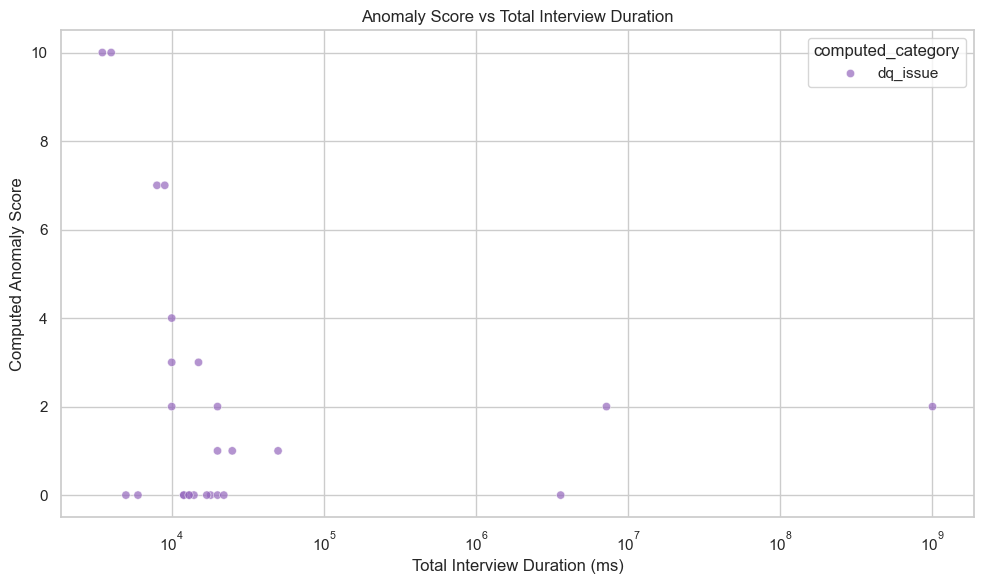

In [48]:
if 'V-01_total_interview_duration_ms' in df.columns and 'computed_anomaly_score' in df.columns:
    plt.figure(figsize=(10, 6))
    
    # Optional: filter out negative durations or highly extreme outliers for a cleaner plot
    plot_df = df[df['V-01_total_interview_duration_ms'] > 0]
    
    if not plot_df.empty:
        sns.scatterplot(
            data=plot_df, 
            x='V-01_total_interview_duration_ms', 
            y='computed_anomaly_score',
            hue='computed_category',
            palette={'normal':'#2ca02c', 'suspicious':'#ff7f0e', 'anomalous':'#d62728', 'dq_issue':'#9467bd'},
            alpha=0.7
        )
        plt.title('Anomaly Score vs Total Interview Duration')
        plt.xlabel('Total Interview Duration (ms)')
        plt.ylabel('Computed Anomaly Score')
        plt.xscale('log') # Log scale is often better for duration
        plt.tight_layout()
        plt.show()
    else:
        print("No valid duration data to plot.")


# 16. Section-Level Fatigue Analysis
Analyzing section-level features (pauses and section completion) by anomaly category to discover where anomalous respondents start showing fatigue.


C:\Users\Samuel\AppData\Local\Temp\ipykernel_12876\4084205330.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Samuel\AppData\Local\Temp\ipykernel_12876\4084205330.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
C:\Users\Samuel\AppData\Local\Temp\ipykernel_12876\4084205330.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Samuel\AppData\Local\Temp\ipykernel_12876\4084205330.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xtickla

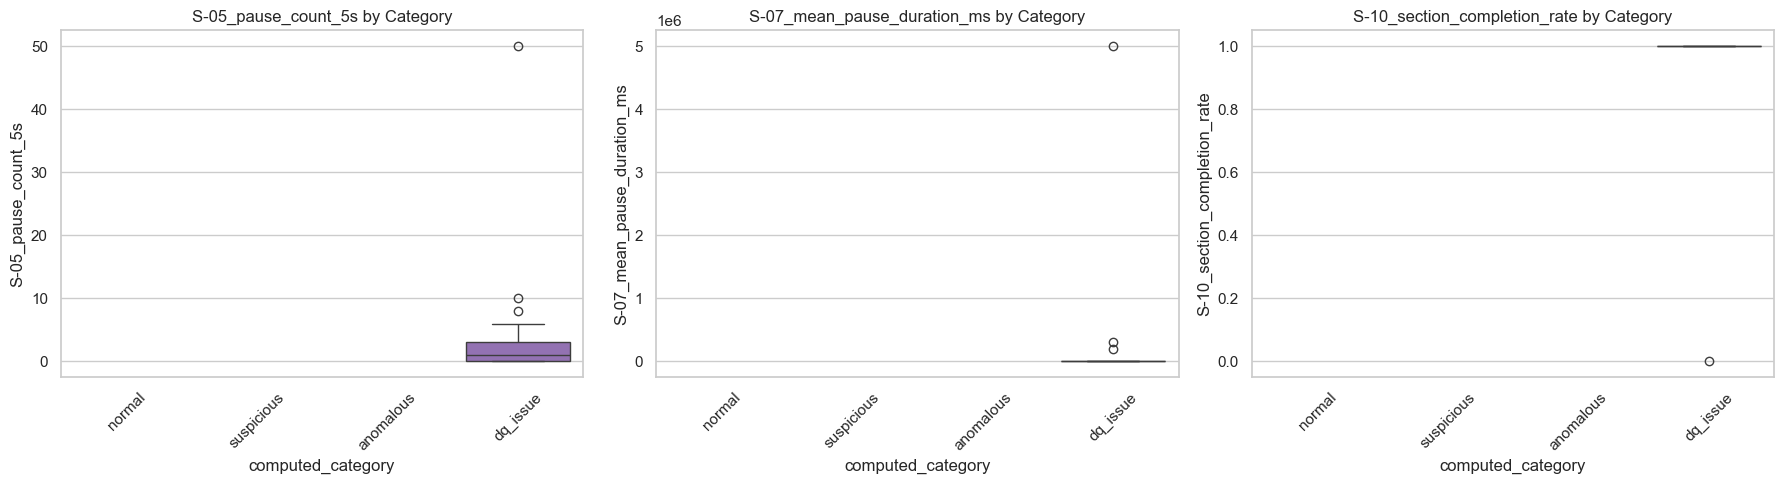

In [49]:
s_features = ['S-05_pause_count_5s', 'S-07_mean_pause_duration_ms', 'S-10_section_completion_rate']
available_s = [f for f in s_features if f in df.columns]

if available_s and 'computed_category' in df.columns:
    fig, axes = plt.subplots(1, len(available_s), figsize=(6 * len(available_s), 5))
    if len(available_s) == 1:
        axes = [axes]
    
    for ax, feat in zip(axes, available_s):
        sns.boxplot(
            data=df, 
            x='computed_category', 
            y=feat, 
            ax=ax, 
            order=['normal', 'suspicious', 'anomalous', 'dq_issue'],
            palette={'normal':'#2ca02c', 'suspicious':'#ff7f0e', 'anomalous':'#d62728', 'dq_issue':'#9467bd'}
        )
        ax.set_title(f'{feat} by Category')
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
    
    plt.tight_layout()
    plt.show()
else:
    print("S-Series parameters not available for Section-Level Fatigue Analysis.")


# 17. Multidimensional Feature Pairplot
Pairwise scatterplots to visually cluster behavioral subsets using timing and structural metrics.


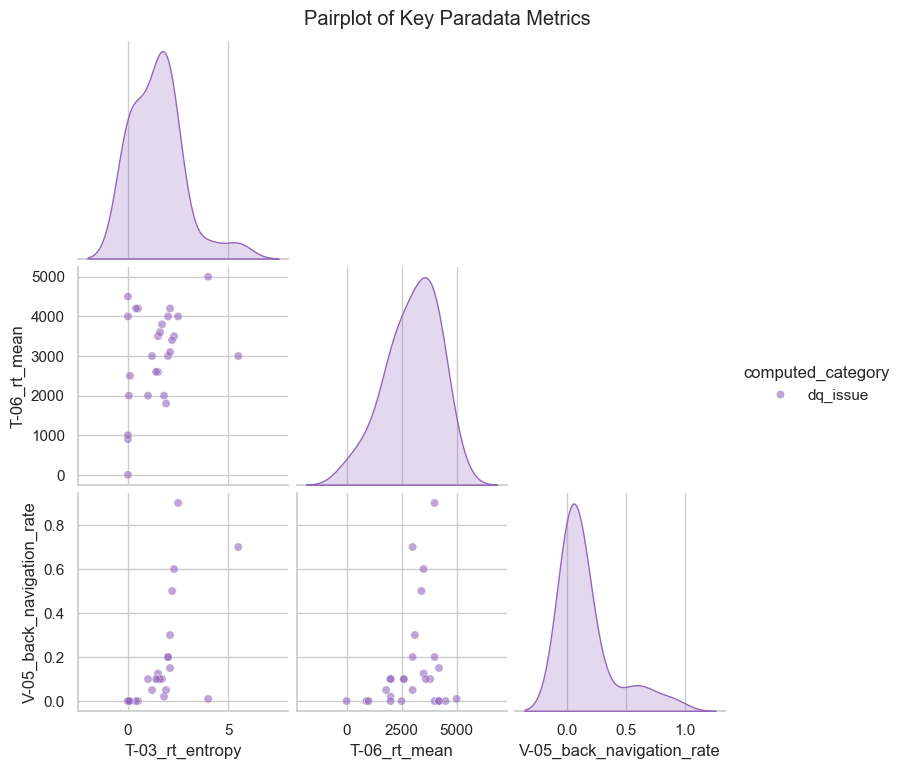

In [50]:
pairplot_features = ['T-03_rt_entropy', 'T-06_rt_mean', 'V-05_back_navigation_rate', 'computed_category']
available_pair = [f for f in pairplot_features if f in df.columns]

if len(available_pair) > 1 and 'computed_category' in available_pair:
    sns.pairplot(
        df[available_pair], 
        hue='computed_category', 
        palette={'normal':'#2ca02c', 'suspicious':'#ff7f0e', 'anomalous':'#d62728', 'dq_issue':'#9467bd'}, 
        corner=True,
        plot_kws={'alpha': 0.6}
    )
    plt.suptitle('Pairplot of Key Paradata Metrics', y=1.02)
    plt.show()
else:
    print("Required features for pairplot are missing.")
